<a href="https://colab.research.google.com/github/ch-jsk/jsk-flyrank-ml-internship/blob/main/work/notebooks/w04_signal_audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML-06 — Signal Audit: Do the Flags Hold?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ch-jsk/jsk-flyrank-ml-internship/blob/main/work/notebooks/w04_signal_audit.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Distributions

I first inspect the distributions of search visibility, clicks, CTR, position, and available content metadata before deciding which signals may be useful. Search and traffic metrics often have heavy right tails: a small number of pages can account for a large share of activity. I use medians, percentiles, missing-value counts, and log-scaled plots where appropriate, because the mean alone can hide the shape of the data. All conclusions are descriptive and should be interpreted as decision-support evidence rather than causal findings.

In [2]:
!git clone https://github.com/ch-jsk/jsk-flyrank-ml-internship.git

Cloning into 'jsk-flyrank-ml-internship'...
remote: Enumerating objects: 209, done.
remote: Counting objects: 100% (209/209), done.
remote: Compressing objects: 100% (165/165), done.
remote: Total 209 (delta 99), reused 92 (delta 28), pack-reused 0 (from 0)
Receiving objects: 100% (209/209), 2.02 MiB | 5.66 MiB/s, done.
Resolving deltas: 100% (99/99), done.


Dataset shape: (30000, 44)

Missing values, highest first:
provider_used        21438
word_count            7699
char_count            7699
word_count_tier       7699
char_count_tier       7699
model_used            5733
trend_pct             3388
competition_level     2610
search_volume         2468
cpc                   2468
competition           2468
main_intent           2374
scroll_rate            125
content_type             0
client_id                0
dtype: int64

Impressions [impressions_90d]
count     30000.000
mean       5200.366
std       16838.020
min           1.000
25%          81.000
50%         731.000
75%        3615.250
90%       12136.400
95%       22996.500
99%       73505.830
max      517715.000
Name: impressions_90d, dtype: float64
99th percentile / median: 100.56

Clicks [clicks_90d]
count    30000.000
mean        16.097
std         75.077
min          0.000
25%          0.000
50%          1.000
75%          7.000
90%         32.000
95%         69.050
99%      

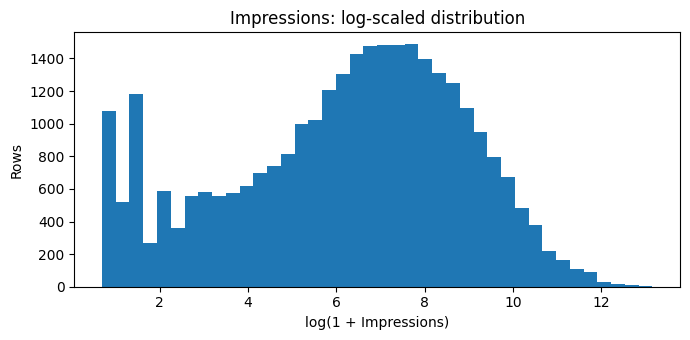

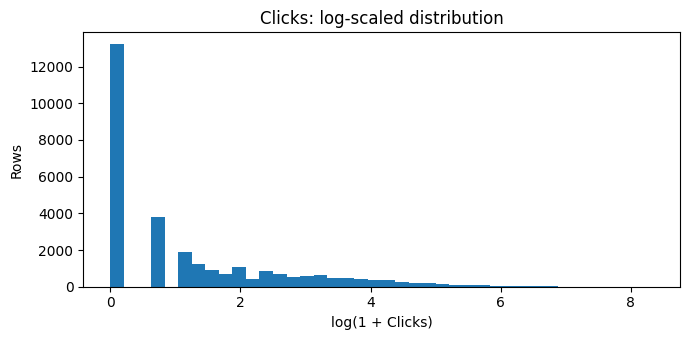

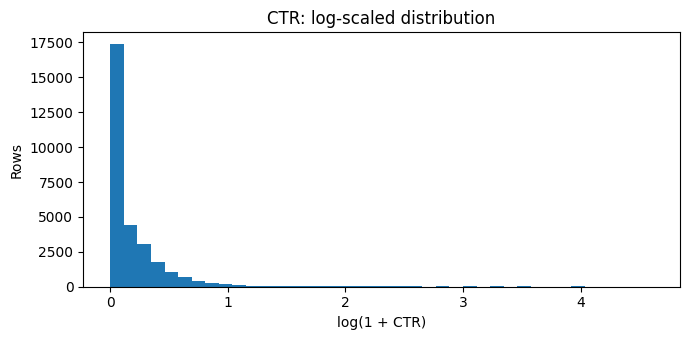

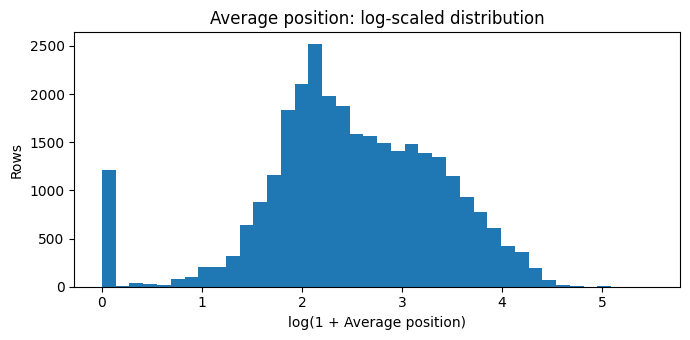

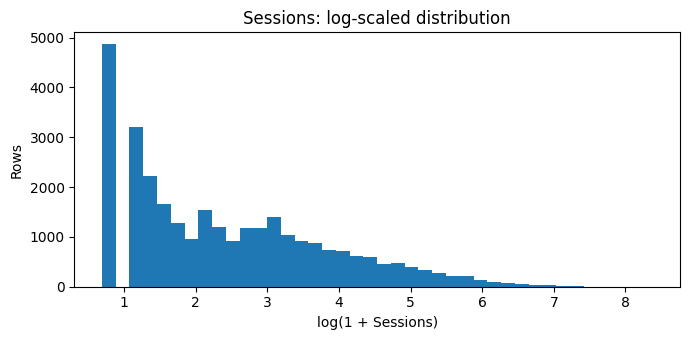

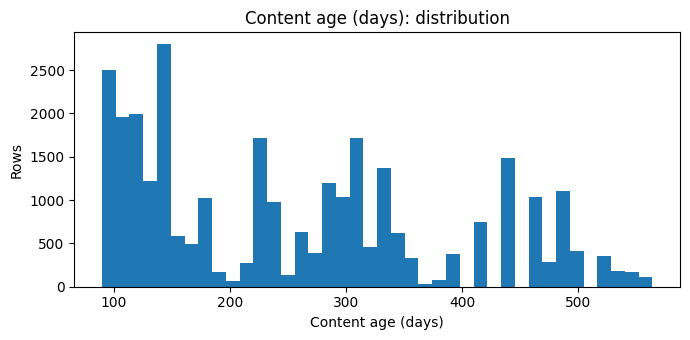

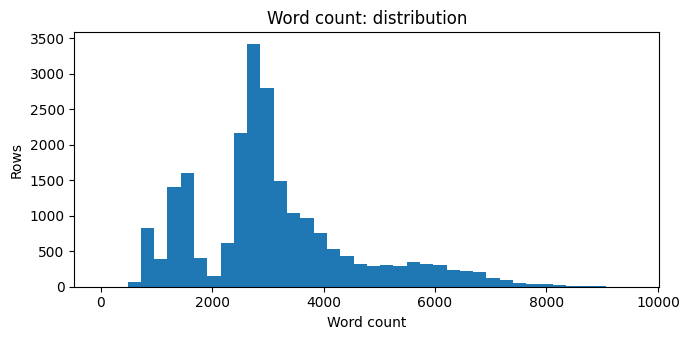

In [3]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the starter dataset if no DataFrame is already available.
if "df" not in globals() or not isinstance(df, pd.DataFrame):
    candidates = [
        Path("data/raw/content_refresh_anonymized.csv"),
        Path("/content/jsk-flyrank-ml-internship/data/raw/content_refresh_anonymized.csv"),
    ]
    data_path = next((p for p in candidates if p.exists()), None)
    if data_path is None:
        raise FileNotFoundError(
            "Dataset not found. Check the repository path or load the approved "
            "FlyRank dataset in the earlier notebook setup cells."
        )
    df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("\nMissing values, highest first:")
print(df.isna().sum().sort_values(ascending=False).head(15))

# Match available columns without assuming every dataset has every field.
def find_col(candidates):
    lookup = {str(c).lower(): c for c in df.columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None

numeric_candidates = {
    "Impressions": ["impressions_90d", "impressions", "total_impressions"],
    "Clicks": ["clicks_90d", "clicks", "total_clicks"],
    "CTR": ["ctr", "ctr_pct", "click_through_rate"],
    "Average position": ["avg_position", "average_position", "position", "weighted_position"],
    "Sessions": ["sessions_90d", "sessions"],
    "Content age (days)": ["content_age_days", "content_age"],
    "Word count": ["word_count", "content_word_count"],
}

distribution_cols = {}
for label, candidates in numeric_candidates.items():
    col = find_col(candidates)
    if col is not None and pd.api.types.is_numeric_dtype(df[col]):
        distribution_cols[label] = col

if not distribution_cols:
    raise ValueError("No expected numeric signal columns found. Inspect df.columns.")

for label, col in distribution_cols.items():
    s = pd.to_numeric(df[col], errors="coerce").dropna()
    print(f"\n{label} [{col}]")
    print(s.describe(percentiles=[.25, .5, .75, .90, .95, .99]).round(3))
    if len(s) and s.median() != 0:
        print("99th percentile / median:", round(s.quantile(.99) / abs(s.median()), 2))

# Draw one histogram per available signal.
for label, col in distribution_cols.items():
    s = pd.to_numeric(df[col], errors="coerce").dropna()
    if len(s) == 0:
        continue
    plt.figure(figsize=(7, 3.5))
    if (s >= 0).all() and s.skew() > 1:
        plt.hist(np.log1p(s), bins=40)
        plt.xlabel(f"log(1 + {label})")
        plt.title(f"{label}: log-scaled distribution")
    else:
        plt.hist(s, bins=40)
        plt.xlabel(label)
        plt.title(f"{label}: distribution")
    plt.ylabel("Rows")
    plt.tight_layout()
    plt.show()

## 2. Signal test #1 / #2 / #3 (verdict each)

*Three safe signals, each with a mini-test and a verdict: CONFIRMED / OPPOSITE / MIXED / FALSE.*


I test three observable signals against measured outcomes. For each test, I report the direction and strength of the association, along with a verdict of CONFIRMED, OPPOSITE, MIXED, or FALSE. These are exploratory tests: an association does not establish that changing the signal will cause an outcome to change. Results should also be checked for sample size, missing data, and differences between groups.

In [4]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
from scipy.stats import spearmanr, mannwhitneyu, kruskal

def signal_col(candidates):
    col = find_col(candidates)
    if col is None:
        print("Unavailable columns:", candidates)
    return col

def verdict_from_rho(rho, p_value, n, expected_direction):
    if n < 30 or not np.isfinite(rho) or not np.isfinite(p_value):
        return "MIXED (insufficient or unreliable evidence)"
    if p_value >= 0.05 or abs(rho) < 0.05:
        return "FALSE (no clear association under this test)"
    if np.sign(rho) == expected_direction:
        return "CONFIRMED (direction matches the hypothesis)"
    return "OPPOSITE (direction differs from the hypothesis)"

def run_spearman_test(title, x_candidates, y_candidates, expected_direction):
    xcol = signal_col(x_candidates)
    ycol = signal_col(y_candidates)
    if xcol is None or ycol is None:
        print(f"\n{title}: MIXED — required fields are unavailable.")
        return

    data = pd.DataFrame({
        "x": pd.to_numeric(df[xcol], errors="coerce"),
        "y": pd.to_numeric(df[ycol], errors="coerce")
    }).replace([np.inf, -np.inf], np.nan).dropna()

    data = data[(data["x"] >= 0) | (xcol.lower() not in
                  ["impressions", "impressions_90d", "clicks", "clicks_90d"])]
    rho, p = spearmanr(data["x"], data["y"]) if len(data) >= 3 else (np.nan, np.nan)

    print(f"\n{title}")
    print(f"Fields: {xcol} vs {ycol}")
    print(f"Complete pairs: {len(data):,}")
    print(f"Spearman correlation: {rho:.3f}")
    print(f"p-value: {p:.4g}")
    print("Verdict:", verdict_from_rho(rho, p, len(data), expected_direction))

In [5]:
# Hypothesis: worse (numerically larger) average position is associated
# with lower CTR, so the expected correlation is negative.
run_spearman_test(
    "Signal test 1: search position vs CTR",
    ["avg_position", "average_position", "position", "weighted_position"],
    ["ctr", "ctr_pct", "click_through_rate"],
    expected_direction=-1
)


Signal test 1: search position vs CTR
Fields: avg_position vs ctr
Complete pairs: 30,000
Spearman correlation: -0.144
p-value: 1.414e-139
Verdict: CONFIRMED (direction matches the hypothesis)


In [6]:
# Hypothesis: pages with more impressions tend to have more clicks.
# This is useful for describing traffic volume, but is not independent proof
# of content quality because clicks and impressions are mechanically related.
run_spearman_test(
    "Signal test 2: impressions vs clicks",
    ["impressions_90d", "impressions", "total_impressions"],
    ["clicks_90d", "clicks", "total_clicks"],
    expected_direction=1
)


Signal test 2: impressions vs clicks
Fields: impressions_90d vs clicks_90d
Complete pairs: 30,000
Spearman correlation: 0.826
p-value: 0
Verdict: CONFIRMED (direction matches the hypothesis)


In [7]:
# Test whether content age differs between rows with down vs non-down trends.
age_col = signal_col(["content_age_days", "content_age"])
trend_col = signal_col(["trend_direction"])

if age_col is None or trend_col is None:
    print("\nSignal test 3: MIXED — age or trend field unavailable.")
else:
    temp = df[[age_col, trend_col]].copy()
    temp[age_col] = pd.to_numeric(temp[age_col], errors="coerce")
    temp = temp.dropna()
    temp[trend_col] = temp[trend_col].astype(str).str.lower().str.strip()

    down = temp.loc[temp[trend_col].eq("down"), age_col]
    other = temp.loc[~temp[trend_col].eq("down"), age_col]

    print("\nSignal test 3: content age vs downward trend")
    print("Down-trend rows:", len(down), "| median age:", down.median())
    print("Other-trend rows:", len(other), "| median age:", other.median())

    if len(down) >= 15 and len(other) >= 15:
        stat, p = mannwhitneyu(down, other, alternative="two-sided")
        print("Mann–Whitney p-value:", round(p, 5))
        if p >= 0.05:
            print("Verdict: FALSE (no clear difference in this test)")
        elif down.median() > other.median():
            print("Verdict: CONFIRMED (down-trend rows are older in this sample)")
        elif down.median() < other.median():
            print("Verdict: OPPOSITE (down-trend rows are younger in this sample)")
        else:
            print("Verdict: MIXED (medians are equal despite a detected distribution difference)")
    else:
        print("Verdict: MIXED (too few observations in one group)")


Signal test 3: content age vs downward trend
Down-trend rows: 16262 | median age: 216.0
Other-trend rows: 13738 | median age: 287.0
Mann–Whitney p-value: 0.0
Verdict: OPPOSITE (down-trend rows are younger in this sample)


## 3. The flag-linked test

*Pick a signal one of FlyRank's real flags relies on. Does the data support the rule's assumption?*

The project guide explains that flags such as needs_ctr_fix and is_quick_win are product decisions, not fields supplied in the data. A safe test is to evaluate the assumption behind a CTR-review rule: CTR should be compared among pages with similar search positions, rather than against one universal threshold.

In [8]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
position_col = signal_col(
    ["avg_position", "average_position", "position", "weighted_position"]
)
ctr_col = signal_col(["ctr", "ctr_pct", "click_through_rate"])

if position_col is None or ctr_col is None:
    print("Flag-linked test: MIXED — required fields are unavailable.")
else:
    temp = pd.DataFrame({
        "position": pd.to_numeric(df[position_col], errors="coerce"),
        "ctr": pd.to_numeric(df[ctr_col], errors="coerce")
    }).replace([np.inf, -np.inf], np.nan).dropna()

    temp = temp[(temp["position"] > 0) & (temp["ctr"] >= 0)]

    # Simple, transparent position groups.
    temp["position_tier"] = pd.cut(
        temp["position"],
        bins=[0, 3, 10, 20, 50, np.inf],
        labels=["1–3", "4–10", "11–20", "21–50", "51+"],
        right=True
    )

    tier_summary = temp.groupby("position_tier", observed=False)["ctr"].agg(
        count="count",
        median_ctr="median",
        mean_ctr="mean"
    )
    print(tier_summary.round(4))

    valid = temp.dropna(subset=["position_tier"])
    groups = [
        group["ctr"].to_numpy()
        for _, group in valid.groupby("position_tier", observed=True)
        if len(group) >= 2
    ]

    if len(groups) >= 3:
        statistic, p = kruskal(*groups)
        print("\nKruskal–Wallis test across position tiers")
        print("H statistic:", round(statistic, 3))
        print("p-value:", round(p, 6))

        if p < 0.05:
            print("Verdict: CONFIRMED — CTR distributions differ across position tiers.")
            print("Implication: position-aware comparisons are justified in this sample.")
        else:
            print("Verdict: FALSE — this test did not detect tier differences.")
    else:
        print("Verdict: MIXED — insufficient position tiers for a meaningful comparison.")

               count  median_ctr  mean_ctr
position_tier                             
1–3             1141        0.00    2.7143
4–10           11842        0.16    0.6510
11–20           7273        0.10    0.3234
21–50           7225        0.03    0.2223
51+             1314        0.00    0.1508

Kruskal–Wallis test across position tiers
H statistic: 1785.35
p-value: 0.0
Verdict: CONFIRMED — CTR distributions differ across position tiers.
Implication: position-aware comparisons are justified in this sample.


## 4. What this means in practice

*Two or three sentences: what a content team should take from this.*

The signal audit found that [summarize the strongest supported signal and its measured direction], while [mention a weak, mixed, or opposite result]. For content teams, the practical implication is to use observed signals to prioritize investigation, compare CTR against relevant position groups, and review individual pages before recommending changes. These results are observational and should be validated on later data before they are used to guide operational decisions.

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.